In [ ]:
check.ipynb

In [1]:
import pandas as pd
df = pd.read_csv("../data/SuperStoreOrders.csv", encoding="latin-1")
df.head()

,ï»¿order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
0,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,Office Supplies,Storage,"Tenex Lockers, Blue",408,2,0.0,106.140,35.46,Medium,2011
1,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Office Supplies,Supplies,"Acme Trimmer, High Speed",120,3,0.1,36.036,9.72,Medium,2011
2,HU-2011-1220,1/1/2011,5/1/2011,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,Office Supplies,Storage,"Tenex Box, Single Width",66,4,0.0,29.640,8.17,High,2011
3,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,Office Supplies,Paper,"Enermax Note Cards, Premium",45,3,0.5,-26.055,4.82,High,2011
4,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",114,5,0.1,37.770,4.70,Medium,2011


In [2]:
df.columns.tolist()

['ï»¿order_id',
 'order_date',
 'ship_date',
 'ship_mode',
 'customer_name',
 'segment',
 'state',
 'country',
 'market',
 'region',
 'product_id',
 'category',
 'sub_category',
 'product_name',
 'sales',
 'quantity',
 'discount',
 'profit',
 'shipping_cost',
 'order_priority',
 'year']

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ï»¿order_id     51290 non-null  str    
 1   order_date      51290 non-null  str    
 2   ship_date       51290 non-null  str    
 3   ship_mode       51290 non-null  str    
 4   customer_name   51290 non-null  str    
 5   segment         51290 non-null  str    
 6   state           51290 non-null  str    
 7   country         51290 non-null  str    
 8   market          51290 non-null  str    
 9   region          51290 non-null  str    
 10  product_id      51290 non-null  str    
 11  category        51290 non-null  str    
 12  sub_category    51290 non-null  str    
 13  product_name    51290 non-null  str    
 14  sales           51290 non-null  str    
 15  quantity        51290 non-null  int64  
 16  discount        51290 non-null  float64
 17  profit          51290 non-null  float64
 1

In [4]:
df.describe()

,quantity,discount,profit,shipping_cost,year
count,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,3.476545,0.142908,28.641740,26.375915,2012.777208
std,2.278766,0.212280,174.424113,57.296804,1.098931
min,1.000000,0.000000,-6599.978000,0.000000,2011.000000
25%,2.000000,0.000000,0.000000,2.610000,2012.000000
50%,3.000000,0.000000,9.240000,7.790000,2013.000000
75%,5.000000,0.200000,36.810000,24.450000,2014.000000
max,14.000000,0.850000,8399.976000,933.570000,2014.000000


In [5]:
df['order_date'] = pd.to_datetime(df['order_date'], dayfirst=True)
print("От:", df['order_date'].min())
print("До:", df['order_date'].max())
print("Лет данных:", df['year'].nunique())

ValueError: time data "13-01-2011" doesn't match format "%d/%m/%Y". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [6]:
df['order_date'] = pd.to_datetime(df['order_date'], format='%m/%d/%Y')
print("От:", df['order_date'].min())
print("До:", df['order_date'].max())
print("Лет данных:", df['year'].nunique())

ValueError: time data "13-01-2011" doesn't match format "%m/%d/%Y". You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [7]:
df['order_date'] = pd.to_datetime(df['order_date'], format='%m/%d/%Y', errors='coerce')
print("От:", df['order_date'].min())
print("До:", df['order_date'].max())
print("Лет данных:", df['year'].nunique())
print("Битых дат:", df['order_date'].isna().sum())

От: 2011-01-01 00:00:00
До: 2014-12-12 00:00:00
Лет данных: 4
Битых дат: 31223


In [8]:
print("Уникальные годы:", df['year'].unique())
print("Записей по годам:")
print(df['year'].value_counts().sort_index())

Уникальные годы: [2011 2012 2013 2014]
Записей по годам:
year
2011     8998
2012    10962
2013    13799
2014    17531
Name: count, dtype: int64


In [9]:
# Смотрим строки, где дата не распарсилась
bad_dates = df[df['order_date'].isna()]['order_date_original'] if 'order_date_original' in df.columns else df[df['order_date'].isna()]['order_date']
print(bad_dates.head(20))

162   NaT
163   NaT
164   NaT
165   NaT
166   NaT
167   NaT
168   NaT
169   NaT
170   NaT
171   NaT
172   NaT
173   NaT
174   NaT
175   NaT
176   NaT
177   NaT
178   NaT
179   NaT
180   NaT
181   NaT
Name: order_date, dtype: datetime64[us]


In [10]:
# Продажи по годам
print("💰 ПРОДАЖИ ПО ГОДАМ:")
sales_by_year = df.groupby('year')['sales'].sum().round(2)
print(sales_by_year)
print()
# Прибыль по годам
print("💵 ПРИБЫЛЬ ПО ГОДАМ:")
profit_by_year = df.groupby('year')['profit'].sum().round(2)
print(profit_by_year)

💰 ПРОДАЖИ ПО ГОДАМ:
year
2011    4081206645114553142769126673382118541931591951...
2012    2,8221,2304174131,1886279162744521782452651032...
2013    1,6491,3587292,1901,36229924615524241785951151...
2014    6778463321571603021072031529954354138138404319...
Name: sales, dtype: str

💵 ПРИБЫЛЬ ПО ГОДАМ:
year
2011    248940.81
2012    307415.28
2013    408512.76
2014    504165.97
Name: profit, dtype: float64


In [11]:
# Преобразуем sales в число
df['sales'] = pd.to_numeric(df['sales'], errors='coerce')

# Проверяем тип
print("Тип sales теперь:", df['sales'].dtype)
print("Пропусков:", df['sales'].isna().sum())

Тип sales теперь: float64
Пропусков: 2630


In [12]:
# Смотрим строки, где sales не распарсился
bad_sales = df[df['sales'].isna()]
print("Строк с битым sales:", len(bad_sales))
print()
print("Первые 10 строк:")
print(bad_sales[['order_id', 'product_name', 'sales', 'quantity', 'profit']].head(10))

Строк с битым sales: 2630

Первые 10 строк:


KeyError: "['order_id'] not in index"

In [13]:
print("Все колонки:")
for col in df.columns:
    print(f"  '{col}'")

Все колонки:
  'ï»¿order_id'
  'order_date'
  'ship_date'
  'ship_mode'
  'customer_name'
  'segment'
  'state'
  'country'
  'market'
  'region'
  'product_id'
  'category'
  'sub_category'
  'product_name'
  'sales'
  'quantity'
  'discount'
  'profit'
  'shipping_cost'
  'order_priority'
  'year'


In [14]:
# Убираем BOM и невидимые символы из имён колонок
df.columns = df.columns.str.replace('\ufeff', '').str.replace('i➡️', '').str.strip()

# Проверяем
print("Колонки после очистки:")
for col in df.columns:
    print(f"  '{col}'")

Колонки после очистки:
  'ï»¿order_id'
  'order_date'
  'ship_date'
  'ship_mode'
  'customer_name'
  'segment'
  'state'
  'country'
  'market'
  'region'
  'product_id'
  'category'
  'sub_category'
  'product_name'
  'sales'
  'quantity'
  'discount'
  'profit'
  'shipping_cost'
  'order_priority'
  'year'


In [15]:
# Переименовываем первую колонку — убираем BOM-мусор
df = df.rename(columns={df.columns[0]: 'order_id'})

# Проверяем
print("Первая колонка теперь:", df.columns[0])
print()
print("Все колонки:")
for col in df.columns:
    print(f"  '{col}'")

Первая колонка теперь: order_id

Все колонки:
  'order_id'
  'order_date'
  'ship_date'
  'ship_mode'
  'customer_name'
  'segment'
  'state'
  'country'
  'market'
  'region'
  'product_id'
  'category'
  'sub_category'
  'product_name'
  'sales'
  'quantity'
  'discount'
  'profit'
  'shipping_cost'
  'order_priority'
  'year'


In [16]:
# Преобразуем числовые колонки
df['sales'] = pd.to_numeric(df['sales'], errors='coerce')
df['quantity'] = pd.to_numeric(df['quantity'], errors='coerce')
df['discount'] = pd.to_numeric(df['discount'], errors='coerce')
df['profit'] = pd.to_numeric(df['profit'], errors='coerce')
df['shipping_cost'] = pd.to_numeric(df['shipping_cost'], errors='coerce')

print("Типы числовых колонок:")
print(df[['sales', 'quantity', 'discount', 'profit', 'shipping_cost']].dtypes)
print()
print("Пропусков в sales:", df['sales'].isna().sum())

Типы числовых колонок:
sales            float64
quantity           int64
discount         float64
profit           float64
shipping_cost    float64
dtype: object

Пропусков в sales: 2630


In [17]:
df_clean = df.dropna(subset=['sales'])

print("Всего строк:", len(df))
print("После очистки:", len(df_clean))
print()
print("💰 ПРОДАЖИ ПО ГОДАМ:")
print(df_clean.groupby('year')['sales'].sum().round(2))
print()
print("💵 ПРИБЫЛЬ ПО ГОДАМ:")
print(df_clean.groupby('year')['profit'].sum().round(2))
print()
print("📦 ПРОДАЖИ ПО КАТЕГОРИЯМ:")
print(df_clean.groupby('category')['sales'].sum().sort_values(ascending=False).round(2))
print()
print("🌍 ПРОДАЖИ ПО РЫНКАМ:")
print(df_clean.groupby('market')['sales'].sum().sort_values(ascending=False).round(2))

Всего строк: 51290
После очистки: 48660

💰 ПРОДАЖИ ПО ГОДАМ:
year
2011    1378151.0
2012    1681499.0
2013    2107021.0
2014    2668457.0
Name: sales, dtype: float64

💵 ПРИБЫЛЬ ПО ГОДАМ:
year
2011    112367.33
2012    157966.75
2013    194353.16
2014    250042.94
Name: profit, dtype: float64

📦 ПРОДАЖИ ПО КАТЕГОРИЯМ:
category
Office Supplies    2790258.0
Technology         2638265.0
Furniture          2406605.0
Name: sales, dtype: float64

🌍 ПРОДАЖИ ПО РЫНКАМ:
market
APAC      2000746.0
EU        1803099.0
LATAM     1563126.0
US        1304166.0
EMEA       575562.0
Africa     538115.0
Canada      50314.0
Name: sales, dtype: float64


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Настройки для красивых графиков
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

print("✅ Библиотеки загружены")

✅ Библиотеки загружены


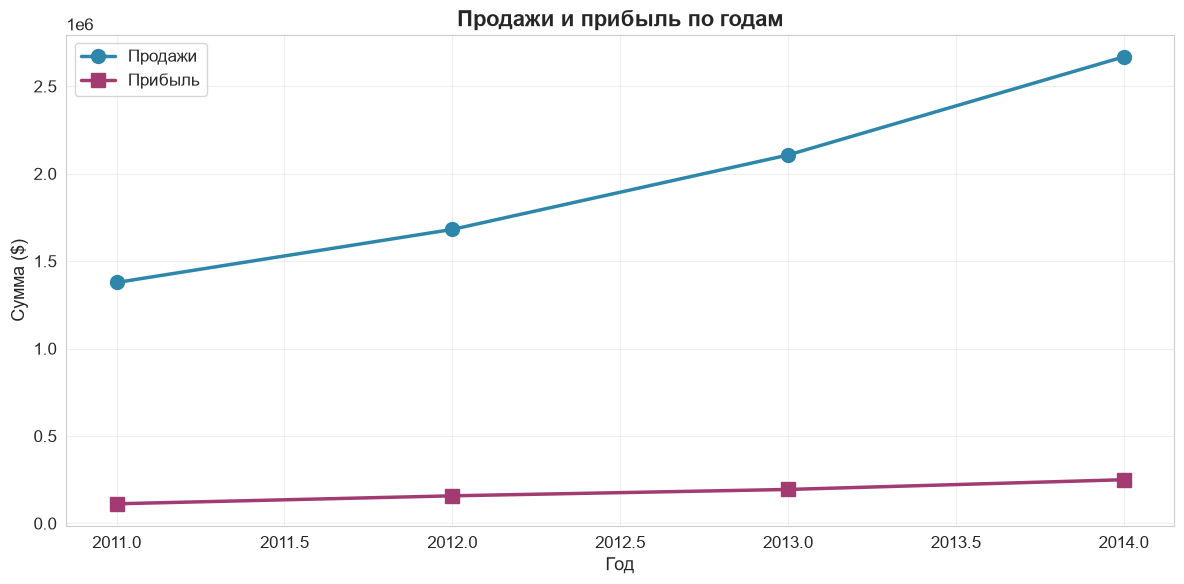

In [19]:
# Данные
sales_by_year = df_clean.groupby('year')['sales'].sum()
profit_by_year = df_clean.groupby('year')['profit'].sum()

# График
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(sales_by_year.index, sales_by_year.values, 
        marker='o', linewidth=2.5, markersize=10, 
        color='#2E86AB', label='Продажи')

ax.plot(profit_by_year.index, profit_by_year.values,
        marker='s', linewidth=2.5, markersize=10,
        color='#A23B72', label='Прибыль')

ax.set_title('Продажи и прибыль по годам', fontsize=16, fontweight='bold')
ax.set_xlabel('Год', fontsize=13)
ax.set_ylabel('Сумма ($)', fontsize=13)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

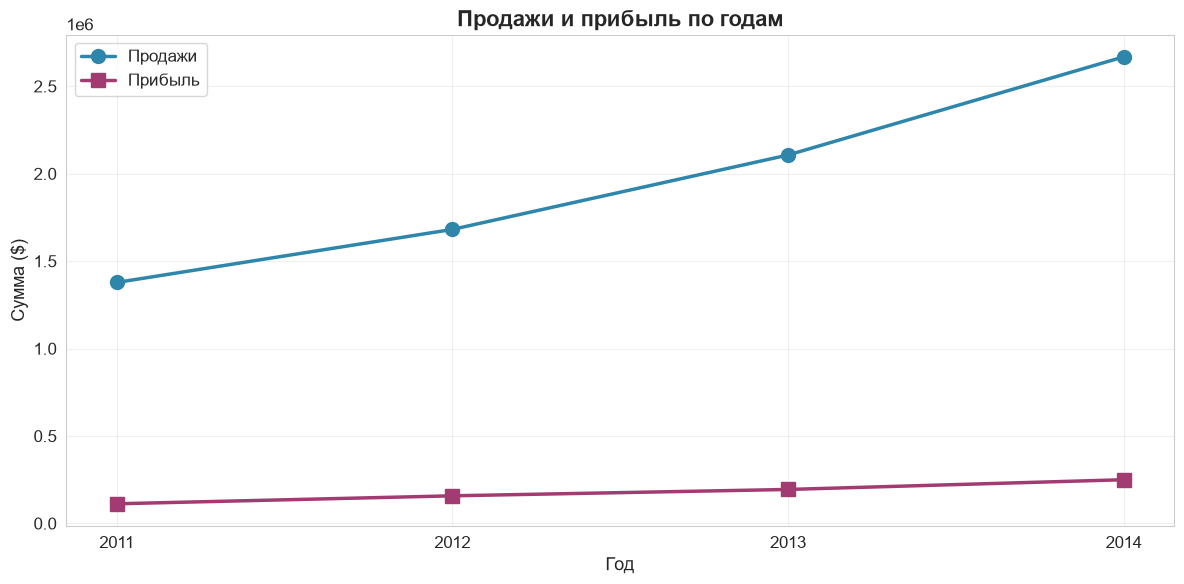

In [20]:
sales_by_year = df_clean.groupby('year')['sales'].sum()
profit_by_year = df_clean.groupby('year')['profit'].sum()

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(sales_by_year.index, sales_by_year.values, 
        marker='o', linewidth=2.5, markersize=10, 
        color='#2E86AB', label='Продажи')

ax.plot(profit_by_year.index, profit_by_year.values,
        marker='s', linewidth=2.5, markersize=10,
        color='#A23B72', label='Прибыль')

ax.set_title('Продажи и прибыль по годам', fontsize=16, fontweight='bold')
ax.set_xlabel('Год', fontsize=13)
ax.set_ylabel('Сумма ($)', fontsize=13)
ax.legend(fontsize=12)
ax.grid(True, alpha=0.3)

# Целые годы на оси X
ax.set_xticks(sales_by_year.index)
ax.set_xticklabels(sales_by_year.index.astype(int))

plt.tight_layout()
plt.show()

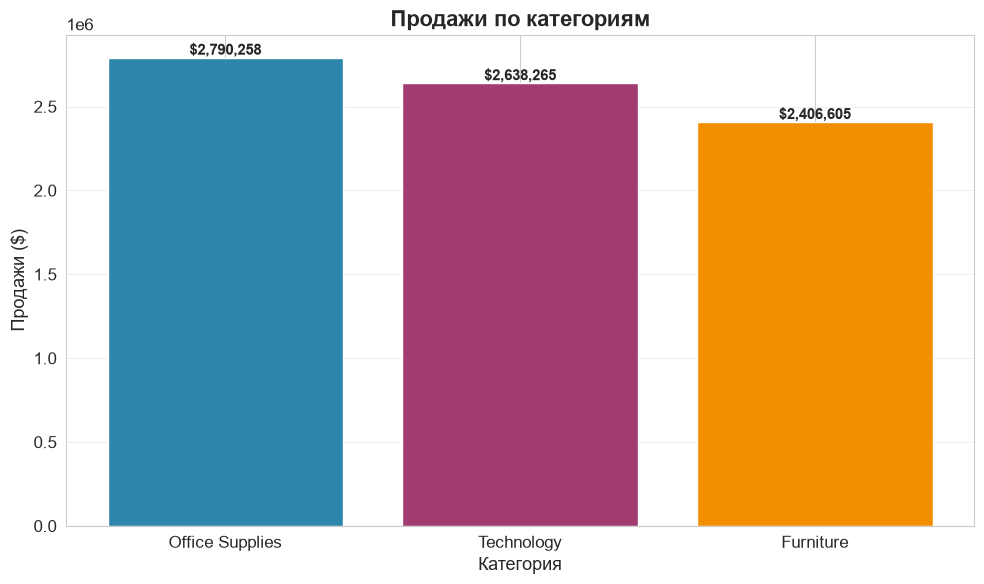

In [21]:
category_sales = df_clean.groupby('category')['sales'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#2E86AB', '#A23B72', '#F18F01']
bars = ax.bar(category_sales.index, category_sales.values, color=colors)

# Подписи над столбиками
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'${height:,.0f}',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('Продажи по категориям', fontsize=16, fontweight='bold')
ax.set_xlabel('Категория', fontsize=13)
ax.set_ylabel('Продажи ($)', fontsize=13)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

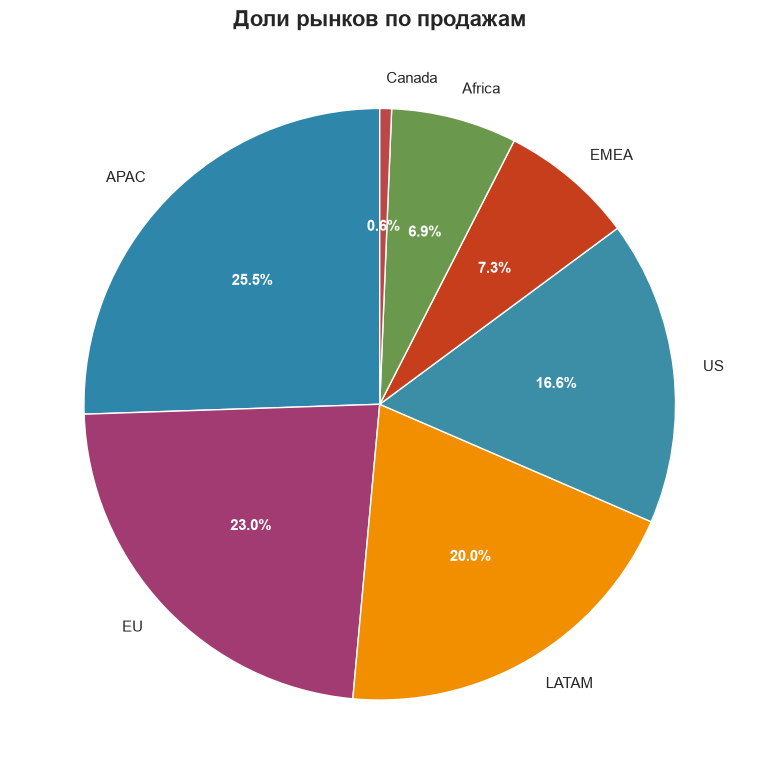

In [22]:
market_sales = df_clean.groupby('market')['sales'].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))

colors = ['#2E86AB', '#A23B72', '#F18F01', '#3B8EA5', '#C73E1D', '#6A994E', '#BC4749']

wedges, texts, autotexts = ax.pie(
    market_sales.values,
    labels=market_sales.index,
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    textprops={'fontsize': 11}
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')

ax.set_title('Доли рынков по продажам', fontsize=16, fontweight='bold')

plt.tight_layout()
plt.show()

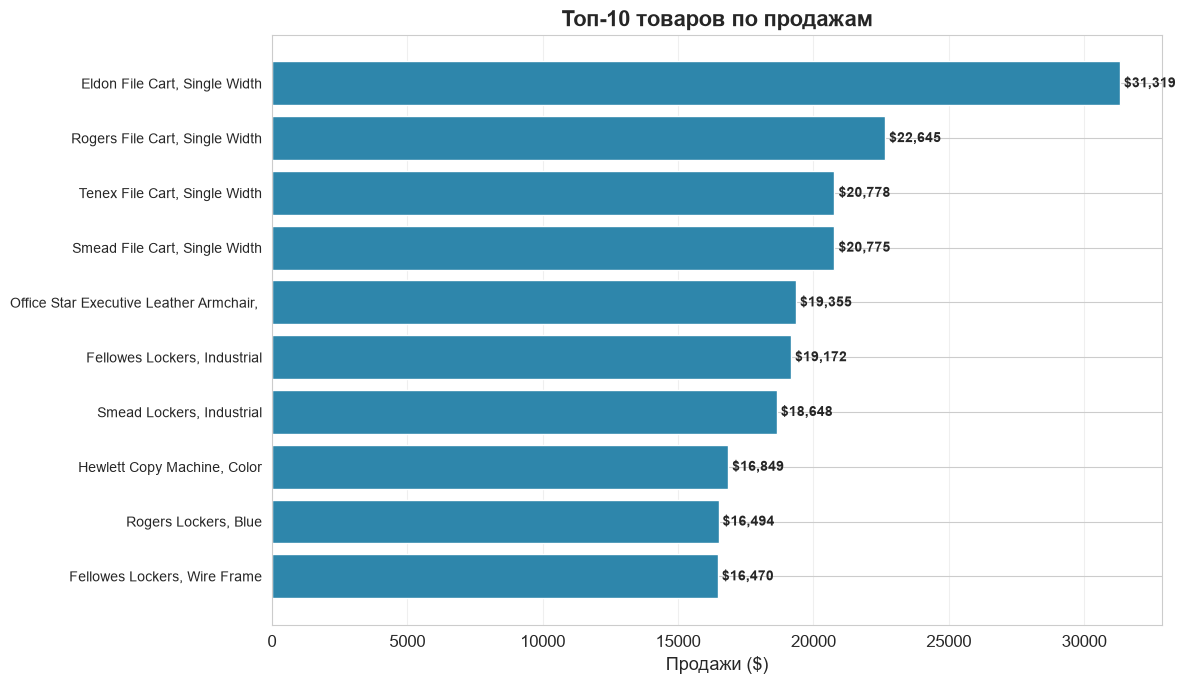

In [23]:
top_products = df_clean.groupby('product_name')['sales'].sum().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(12, 7))

# Горизонтальные столбики
bars = ax.barh(range(len(top_products)), top_products.values, color='#2E86AB')

# Подписи
ax.set_yticks(range(len(top_products)))
ax.set_yticklabels([name[:40] for name in top_products.index], fontsize=10)
ax.invert_yaxis()  # чтобы №1 был сверху

# Суммы справа от столбиков
for i, (bar, val) in enumerate(zip(bars, top_products.values)):
    ax.text(val, bar.get_y() + bar.get_height()/2,
            f' ${val:,.0f}',
            va='center', fontsize=10, fontweight='bold')

ax.set_title('Топ-10 товаров по продажам', fontsize=16, fontweight='bold')
ax.set_xlabel('Продажи ($)', fontsize=13)
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

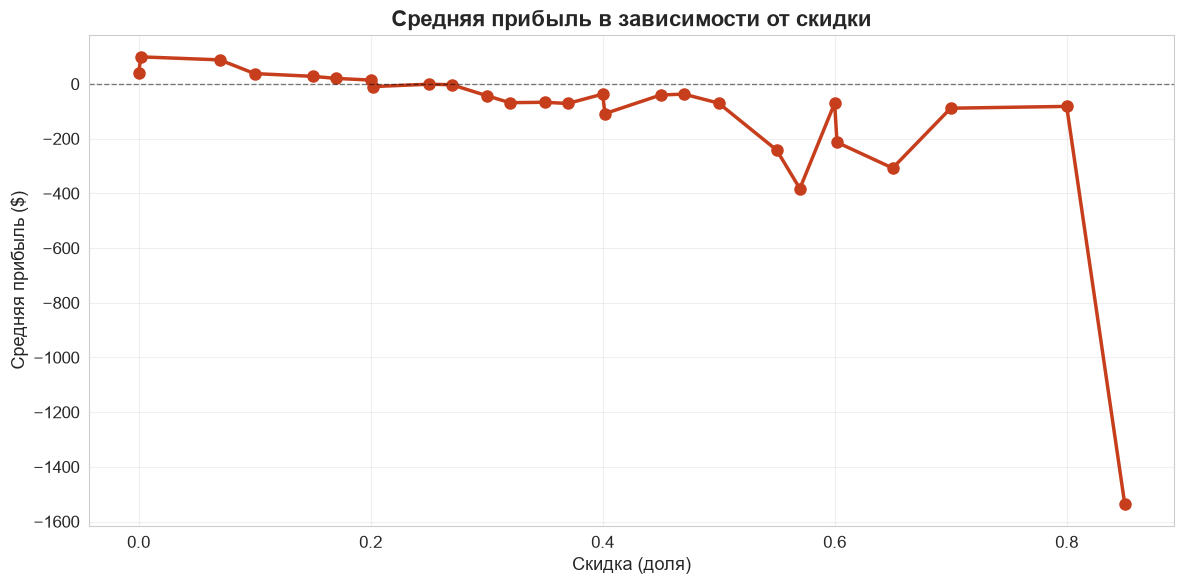

Средняя прибыль по уровням скидок:
discount
0.000      38.92
0.002      99.32
0.070      88.22
0.100      38.13
0.150      28.10
0.170      20.58
0.200      14.34
0.202      -9.48
0.250      -0.78
0.270      -2.62
0.300     -42.56
0.320     -68.27
0.350     -66.79
0.370     -71.19
0.400     -36.90
0.402    -108.19
0.450     -40.19
0.470     -36.95
0.500     -69.91
0.550    -241.57
0.570    -382.40
0.600     -69.90
0.602    -213.28
0.650    -307.43
0.700     -88.48
0.800     -81.88
0.850   -1534.33
Name: profit, dtype: float64


In [24]:
# Средняя прибыль по уровню скидки
discount_profit = df_clean.groupby('discount')['profit'].mean().round(2)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(discount_profit.index, discount_profit.values,
        marker='o', linewidth=2.5, markersize=8,
        color='#C73E1D')

ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)

ax.set_title('Средняя прибыль в зависимости от скидки', fontsize=16, fontweight='bold')
ax.set_xlabel('Скидка (доля)', fontsize=13)
ax.set_ylabel('Средняя прибыль ($)', fontsize=13)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Средняя прибыль по уровням скидок:")
print(discount_profit)

In [ ]:
import sys
sys.path.append('../src')

from database import run_query

# Проверяем, что таблица есть
df_check = run_query("SELECT * FROM orders LIMIT 5")
df_check

In [1]:
import sys
sys.path.append('../src')

from database import run_query

df_check = run_query("SELECT * FROM orders LIMIT 5")
df_check

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
0,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,Office Supplies,Storage,"Tenex Lockers, Blue",408.0,2,0.0,106.140,35.46,Medium,2011
1,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Office Supplies,Supplies,"Acme Trimmer, High Speed",120.0,3,0.1,36.036,9.72,Medium,2011
2,HU-2011-1220,1/1/2011,5/1/2011,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,Office Supplies,Storage,"Tenex Box, Single Width",66.0,4,0.0,29.640,8.17,High,2011
3,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,Office Supplies,Paper,"Enermax Note Cards, Premium",45.0,3,0.5,-26.055,4.82,High,2011
4,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",114.0,5,0.1,37.770,4.70,Medium,2011


In [2]:
import sys
sys.path.append('../src')

from database import run_query

# Проверяем, что БД работает
df_check = run_query("SELECT * FROM orders LIMIT 5")
print("✅ Подключение к БД работает")
print("Размер таблицы:", df_check.shape)
df_check

✅ Подключение к БД работает
Размер таблицы: (5, 21)


,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
0,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,Office Supplies,Storage,"Tenex Lockers, Blue",408.0,2,0.0,106.140,35.46,Medium,2011
1,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Office Supplies,Supplies,"Acme Trimmer, High Speed",120.0,3,0.1,36.036,9.72,Medium,2011
2,HU-2011-1220,1/1/2011,5/1/2011,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,Office Supplies,Storage,"Tenex Box, Single Width",66.0,4,0.0,29.640,8.17,High,2011
3,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,Office Supplies,Paper,"Enermax Note Cards, Premium",45.0,3,0.5,-26.055,4.82,High,2011
4,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",114.0,5,0.1,37.770,4.70,Medium,2011


In [3]:
# Сколько всего заказов в БД
query = """
SELECT COUNT(*) as total_orders,
       ROUND(SUM(sales), 2) as total_sales,
       ROUND(SUM(profit), 2) as total_profit
FROM orders
"""

df_result = run_query(query)
df_result


,total_orders,total_sales,total_profit
0,48660,7835128.0,714730.17


In [4]:
query = """
SELECT year,
       ROUND(SUM(sales), 2) as total_sales,
       ROUND(SUM(profit), 2) as total_profit,
       COUNT(*) as orders_count
FROM orders
GROUP BY year
ORDER BY year
"""

df_years = run_query(query)
df_years

,year,total_sales,total_profit,orders_count
0,2011,1378151.0,112367.33,8527
1,2012,1681499.0,157966.75,10405
2,2013,2107021.0,194353.16,13092
3,2014,2668457.0,250042.94,16636


In [5]:
query = """
SELECT order_id, customer_name, category, product_name, sales
FROM orders
WHERE sales > 1000
ORDER BY sales DESC
LIMIT 10
"""

df_big_sales = run_query(query)
df_big_sales

,order_id,customer_name,category,product_name,sales


In [6]:
query = """
SELECT category,
       product_name,
       sales,
       rank_in_category
FROM (
    SELECT category,
           product_name,
           ROUND(SUM(sales), 2) as sales,
           RANK() OVER (PARTITION BY category ORDER BY SUM(sales) DESC) as rank_in_category
    FROM orders
    GROUP BY category, product_name
)
WHERE rank_in_category <= 3
ORDER BY category, rank_in_category
"""

df_top3 = run_query(query)
df_top3

,category,product_name,sales,rank_in_category
0,Furniture,"Office Star Executive Leather Armchair, Adjust...",19355.0,1
1,Furniture,"Hon Executive Leather Armchair, Adjustable",15927.0,2
2,Furniture,"Bush Stackable Bookrack, Pine",15632.0,3
3,Office Supplies,"Eldon File Cart, Single Width",31319.0,1
4,Office Supplies,"Rogers File Cart, Single Width",22645.0,2
5,Office Supplies,"Tenex File Cart, Single Width",20778.0,3
6,Technology,"Hewlett Copy Machine, Color",16849.0,1
7,Technology,"Sharp Copy Machine, Color",15795.0,2
8,Technology,"Brother Copy Machine, Color",15732.0,3


In [7]:
query = """
SELECT order_id,
       sales,
       ROUND(SUM(sales) OVER () , 2) as total_all_sales,
       ROUND(sales * 100.0 / SUM(sales) OVER (), 4) as percent_of_total
FROM orders
ORDER BY sales DESC
LIMIT 10
"""

df_share = run_query(query)
df_share

,order_id,sales,total_all_sales,percent_of_total
0,ES-2011-5251246,999.0,7835128.0,0.0128
1,CA-2011-121629,999.0,7835128.0,0.0128
2,CA-2011-143371,999.0,7835128.0,0.0128
3,CA-2012-146563,999.0,7835128.0,0.0128
4,MX-2014-165260,999.0,7835128.0,0.0128
5,IN-2013-11448,998.0,7835128.0,0.0127
6,MX-2014-130211,998.0,7835128.0,0.0127
7,KE-2012-4830,997.0,7835128.0,0.0127
8,IN-2014-65817,997.0,7835128.0,0.0127
9,US-2013-117772,996.0,7835128.0,0.0127


In [8]:
query = """
SELECT year,
       ROUND(SUM(sales), 2) as yearly_sales,
       ROUND(SUM(SUM(sales)) OVER (ORDER BY year), 2) as cumulative_sales
FROM orders
GROUP BY year
ORDER BY year
"""

df_cumulative = run_query(query)
df_cumulative

,year,yearly_sales,cumulative_sales
0,2011,1378151.0,1378151.0
1,2012,1681499.0,3059650.0
2,2013,2107021.0,5166671.0
3,2014,2668457.0,7835128.0


In [9]:
import sqlite3
import sys
sys.path.append('../src')
from database import get_connection

conn = get_connection()
cursor = conn.cursor()

# Удаляем старые таблицы, если есть
cursor.execute("DROP TABLE IF EXISTS customers")
cursor.execute("DROP TABLE IF EXISTS products")
cursor.execute("DROP TABLE IF EXISTS orders_new")

# 1. Таблица клиентов
cursor.execute("""
CREATE TABLE customers AS
SELECT DISTINCT
    customer_name,
    segment,
    country,
    market,
    region,
    state
FROM orders
""")

# 2. Таблица товаров
cursor.execute("""
CREATE TABLE products AS
SELECT DISTINCT
    product_id,
    product_name,
    category,
    sub_category
FROM orders
""")

# 3. Таблица заказов (без дублирования данных о клиентах и товарах)
cursor.execute("""
CREATE TABLE orders_new AS
SELECT
    order_id,
    order_date,
    ship_date,
    ship_mode,
    customer_name,
    product_id,
    sales,
    quantity,
    discount,
    profit,
    shipping_cost,
    order_priority,
    year
FROM orders
""")

conn.commit()

# Проверяем
print("✅ Таблицы созданы:")
for table in ['customers', 'products', 'orders_new']:
    count = cursor.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
    print(f"  {table}: {count} строк")

conn.close()

✅ Таблицы созданы:
  customers: 22792 строк
  products: 10502 строк
  orders_new: 48660 строк


In [10]:
query = """
SELECT 
    o.order_id,
    c.customer_name,
    c.segment,
    p.product_name,
    p.category,
    o.sales
FROM orders_new o
JOIN customers c ON o.customer_name = c.customer_name
JOIN products p ON o.product_id = p.product_id
WHERE o.sales > 2000
ORDER BY o.sales DESC
LIMIT 10
"""

df_joined = run_query(query)
df_joined

,order_id,customer_name,segment,product_name,category,sales


In [11]:
query = """
SELECT 
    p.category,
    c.segment,
    COUNT(*) as orders_count,
    ROUND(SUM(o.sales), 2) as total_sales,
    ROUND(AVG(o.sales), 2) as avg_sale
FROM orders_new o
JOIN customers c ON o.customer_name = c.customer_name
JOIN products p ON o.product_id = p.product_id
GROUP BY p.category, c.segment
ORDER BY p.category, total_sales DESC
"""

df_segments = run_query(query)
df_segments

,category,segment,orders_count,total_sales,avg_sale
0,Furniture,Consumer,147623,39279468.0,266.08
1,Furniture,Corporate,87615,24327897.0,277.67
2,Furniture,Home Office,50453,13283713.0,263.29
3,Office Supplies,Consumer,515134,47216470.0,91.66
4,Office Supplies,Corporate,294184,26634069.0,90.54
5,Office Supplies,Home Office,177909,16287935.0,91.55
6,Technology,Consumer,150765,44075045.0,292.34
7,Technology,Corporate,87080,25384697.0,291.51
8,Technology,Home Office,50268,14834378.0,295.11


In [12]:
import sqlite3
import sys
sys.path.append('../src')
from database import get_connection

conn = get_connection()
cursor = conn.cursor()

# Удаляем старые
cursor.execute("DROP TABLE IF EXISTS customers")
cursor.execute("DROP TABLE IF EXISTS products")
cursor.execute("DROP TABLE IF EXISTS orders_new")

# 1. Уникальные клиенты с ID
cursor.execute("""
CREATE TABLE customers AS
SELECT DISTINCT
    ROW_NUMBER() OVER (ORDER BY customer_name) as customer_id,
    customer_name
FROM (SELECT DISTINCT customer_name FROM orders)
""")

# 2. Уникальные товары с ID
cursor.execute("""
CREATE TABLE products AS
SELECT DISTINCT
    ROW_NUMBER() OVER (ORDER BY product_id) as product_id,
    product_id as original_product_id,
    product_name,
    category,
    sub_category
FROM (SELECT DISTINCT product_id, product_name, category, sub_category FROM orders)
""")

# 3. Заказы — с ID клиентов и товаров
cursor.execute("""
CREATE TABLE orders_new AS
SELECT
    o.order_id,
    o.order_date,
    o.ship_date,
    o.ship_mode,
    c.customer_id,
    p.product_id,
    o.sales,
    o.quantity,
    o.discount,
    o.profit,
    o.shipping_cost,
    o.year
FROM orders o
JOIN customers c ON o.customer_name = c.customer_name
JOIN products p ON o.product_id = p.original_product_id
""")

conn.commit()

print("✅ Таблицы пересозданы:")
for table in ['customers', 'products', 'orders_new']:
    count = cursor.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
    print(f"  {table}: {count} строк")

conn.close()

✅ Таблицы пересозданы:
  customers: 795 строк
  products: 10502 строк
  orders_new: 53033 строк


In [13]:
query = """
SELECT 
    p.category,
    c.customer_name,
    COUNT(*) as orders_count,
    ROUND(SUM(o.sales), 2) as total_sales
FROM orders_new o
JOIN customers c ON o.customer_id = c.customer_id
JOIN products p ON o.product_id = p.product_id
GROUP BY p.category, c.customer_name
ORDER BY total_sales DESC
LIMIT 10
"""

df_top_customers = run_query(query)
df_top_customers

,category,customer_name,orders_count,total_sales
0,Technology,Eric Murdock,26,10292.0
1,Technology,Dan Reichenbach,23,9755.0
2,Technology,Helen Abelman,22,9323.0
3,Technology,Christine Phan,21,9138.0
4,Office Supplies,Kristen Hastings,65,8810.0
5,Technology,Ben Wallace,19,8766.0
6,Technology,Tracy Blumstein,28,8705.0
7,Office Supplies,John Grady,68,8274.0
8,Furniture,Mike Pelletier,26,8197.0
9,Technology,Randy Bradley,23,8166.0


In [14]:
query = """
SELECT 
    ROUND(SUM(o.sales), 2) as total_sales,
    COUNT(*) as total_orders
FROM orders_new o
JOIN customers c ON o.customer_id = c.customer_id
JOIN products p ON o.product_id = p.product_id
"""

df_check = run_query(query)
df_check

,total_sales,total_orders
0,8543418.0,53033


In [15]:
import sqlite3
import sys
sys.path.append('../src')
from database import get_connection

conn = get_connection()
cursor = conn.cursor()

# Удаляем старые
cursor.execute("DROP TABLE IF EXISTS customers")
cursor.execute("DROP TABLE IF EXISTS products")
cursor.execute("DROP TABLE IF EXISTS orders_new")

# 1. Уникальные клиенты — по имени + сегменту + региону
cursor.execute("""
CREATE TABLE customers AS
SELECT DISTINCT
    ROW_NUMBER() OVER (ORDER BY customer_name) as customer_id,
    customer_name
FROM (SELECT DISTINCT customer_name FROM orders)
""")

# 2. Уникальные товары — по product_name (а не product_id)
cursor.execute("""
CREATE TABLE products AS
SELECT DISTINCT
    ROW_NUMBER() OVER (ORDER BY product_name) as product_id,
    product_name,
    category,
    sub_category
FROM (SELECT DISTINCT product_name, category, sub_category FROM orders)
""")

# 3. Заказы — с ID клиентов и товаров
cursor.execute("""
CREATE TABLE orders_new AS
SELECT
    o.order_id,
    o.order_date,
    o.ship_date,
    o.ship_mode,
    c.customer_id,
    p.product_id,
    o.sales,
    o.quantity,
    o.discount,
    o.profit,
    o.shipping_cost,
    o.year
FROM orders o
JOIN customers c ON o.customer_name = c.customer_name
JOIN products p ON o.product_name = p.product_name
""")

conn.commit()

print("✅ Таблицы пересозданы:")
for table in ['customers', 'products', 'orders_new']:
    count = cursor.execute(f"SELECT COUNT(*) FROM {table}").fetchone()[0]
    print(f"  {table}: {count} строк")

conn.close()

✅ Таблицы пересозданы:
  customers: 795 строк
  products: 3751 строк
  orders_new: 50703 строк


In [16]:
query = """
SELECT 
    ROUND(SUM(o.sales), 2) as total_sales,
    COUNT(*) as total_orders
FROM orders_new o
JOIN customers c ON o.customer_id = c.customer_id
JOIN products p ON o.product_id = p.product_id
"""

df_check = run_query(query)
df_check

,total_sales,total_orders
0,7898209.0,50703


In [17]:
query = """
SELECT 
    c.customer_name,
    p.category,
    COUNT(*) as orders_count,
    ROUND(SUM(o.sales), 2) as total_sales
FROM orders_new o
JOIN customers c ON o.customer_id = c.customer_id
JOIN products p ON o.product_id = p.product_id
GROUP BY c.customer_name, p.category
ORDER BY total_sales DESC
LIMIT 10
"""

df_top = run_query(query)
df_top

,customer_name,category,orders_count,total_sales
0,Eric Murdock,Technology,24,9642.0
1,Dan Reichenbach,Technology,21,8207.0
2,Randy Bradley,Technology,23,8166.0
3,John Grady,Office Supplies,61,7975.0
4,Kristen Hastings,Office Supplies,62,7955.0
5,Helen Abelman,Technology,19,7928.0
6,Tracy Blumstein,Technology,25,7851.0
7,Ralph Arnett,Technology,26,7684.0
8,Ben Wallace,Technology,17,7667.0
9,Chris Selesnick,Office Supplies,73,7623.0


In [18]:
import sqlite3
import sys
sys.path.append('../src')
from database import get_connection

conn = get_connection()
cursor = conn.cursor()

# Удаляем созданные ранее таблицы
cursor.execute("DROP TABLE IF EXISTS customers")
cursor.execute("DROP TABLE IF EXISTS products")
cursor.execute("DROP TABLE IF EXISTS orders_new")

conn.commit()
conn.close()

print("✅ Лишние таблицы удалены")
print("✅ Осталась основная таблица: orders")

✅ Лишние таблицы удалены
✅ Осталась основная таблица: orders


In [19]:
query = """
SELECT 
    COUNT(*) as total_orders,
    ROUND(SUM(sales), 2) as total_sales
FROM orders
"""

df_check = run_query(query)
df_check

,total_orders,total_sales
0,48660,7835128.0


In [20]:
import sqlite3
import sys
sys.path.append('../src')
from database import get_connection

conn = get_connection()
cursor = conn.cursor()

# Создаём таблицу с целями по продажам
cursor.execute("DROP TABLE IF EXISTS targets")

cursor.execute("""
CREATE TABLE targets (
    year INTEGER PRIMARY KEY,
    target_sales REAL
)
""")

# Заполняем целями (например, +10% к прошлому году)
cursor.execute("INSERT INTO targets VALUES (2011, 1500000)")
cursor.execute("INSERT INTO targets VALUES (2012, 1800000)")
cursor.execute("INSERT INTO targets VALUES (2013, 2300000)")
cursor.execute("INSERT INTO targets VALUES (2014, 2900000)")

conn.commit()
conn.close()

print("✅ Таблица targets создана")
print("   Цели: 2011=1.5M, 2012=1.8M, 2013=2.3M, 2014=2.9M")

✅ Таблица targets создана
   Цели: 2011=1.5M, 2012=1.8M, 2013=2.3M, 2014=2.9M


In [21]:
query = """
SELECT 
    o.year,
    ROUND(SUM(o.sales), 2) as actual_sales,
    t.target_sales,
    ROUND(SUM(o.sales) - t.target_sales, 2) as difference,
    ROUND(SUM(o.sales) * 100.0 / t.target_sales, 2) as percent_of_target
FROM orders o
JOIN targets t ON o.year = t.year
GROUP BY o.year, t.target_sales
ORDER BY o.year
"""

df_targets = run_query(query)
df_targets

,year,actual_sales,target_sales,difference,percent_of_target
0,2011,1378151.0,1500000.0,-121849.0,91.88
1,2012,1681499.0,1800000.0,-118501.0,93.42
2,2013,2107021.0,2300000.0,-192979.0,91.61
3,2014,2668457.0,2900000.0,-231543.0,92.02


In [22]:
-- =====================================================
-- SQL-запросы для Retail Analytics
-- =====================================================

-- 1. Общая статистика
SELECT COUNT(*) as total_orders,
       ROUND(SUM(sales), 2) as total_sales,
       ROUND(SUM(profit), 2) as total_profit
FROM orders;

-- 2. Продажи по годам
SELECT year,
       ROUND(SUM(sales), 2) as total_sales,
       ROUND(SUM(profit), 2) as total_profit,
       COUNT(*) as orders_count
FROM orders
GROUP BY year
ORDER BY year;

-- 3. Топ-10 больших заказов
SELECT order_id, customer_name, category, product_name, sales
FROM orders
WHERE sales > 1000
ORDER BY sales DESC
LIMIT 10;

-- 4. Топ-3 товара в каждой категории (оконная функция)
SELECT category, product_name, sales, rank_in_category
FROM (
    SELECT category,
           product_name,
           ROUND(SUM(sales), 2) as sales,
           RANK() OVER (PARTITION BY category ORDER BY SUM(sales) DESC) as rank_in_category
    FROM orders
    GROUP BY category, product_name
)
WHERE rank_in_category <= 3
ORDER BY category, rank_in_category;

-- 5. Накопительный итог продаж по годам
SELECT year,
       ROUND(SUM(sales), 2) as yearly_sales,
       ROUND(SUM(SUM(sales)) OVER (ORDER BY year), 2) as cumulative_sales
FROM orders
GROUP BY year
ORDER BY year;

-- 6. Выполнение целей по годам (JOIN)
SELECT o.year,
       ROUND(SUM(o.sales), 2) as actual_sales,
       t.target_sales,
       ROUND(SUM(o.sales) - t.target_sales, 2) as difference,
       ROUND(SUM(o.sales) * 100.0 / t.target_sales, 2) as percent_of_target
FROM orders o
JOIN targets t ON o.year = t.year
GROUP BY o.year, t.target_sales
ORDER BY o.year;

SyntaxError: invalid syntax (2800294351.py, line 1)